In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/justinwshj/accidents/datasets/README.dataset.txt
/kaggle/input/datasets/justinwshj/accidents/datasets/README.roboflow.txt
/kaggle/input/datasets/justinwshj/accidents/datasets/data.yaml
/kaggle/input/datasets/justinwshj/accidents/datasets/test/images/10-79_jpg.rf.779a2c7fd0d90ae50dc2fe439b9a445c.jpg
/kaggle/input/datasets/justinwshj/accidents/datasets/test/images/1042_jpeg_jpg.rf.902d0c2eb7bc19d6e570013272e2fdf5.jpg
/kaggle/input/datasets/justinwshj/accidents/datasets/test/images/1042_jpeg_jpg.rf.dcd2b10e47517ea0292a22f6b9eae93b.jpg
/kaggle/input/datasets/justinwshj/accidents/datasets/test/images/1080_jpeg_jpg.rf.639599a8cf53ae5d4536c597fc75d3d0.jpg
/kaggle/input/datasets/justinwshj/accidents/datasets/test/images/1083_jpeg_jpg.rf.8d9da40de994ddfa6043c4d3f095e5ad.jpg
/kaggle/input/datasets/justinwshj/accidents/datasets/test/images/1107_jpeg_jpg.rf.33889099c7d14c60428b4618ff5953c5.jpg
/kaggle/input/datasets/justinwshj/accidents/datasets/test/images/1107_jpeg_jpg.rf.

# 训练道路车辆事故检测模型

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 37.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import cv2
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weights & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
model = YOLO('yolo11n.pt')

In [5]:
results = model.train(
    data = '/kaggle/input/datasets/justinwshj/accidents/datasets/data.yaml', # 数据集配置文件路径
    epochs = 30, # 训练轮数
    imgsz = 640, # 输入图片大小
    batch = 32 # 批处理大小
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/justinwshj/accidents/datasets/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, o

## 查看训练过程中的性能评估曲线

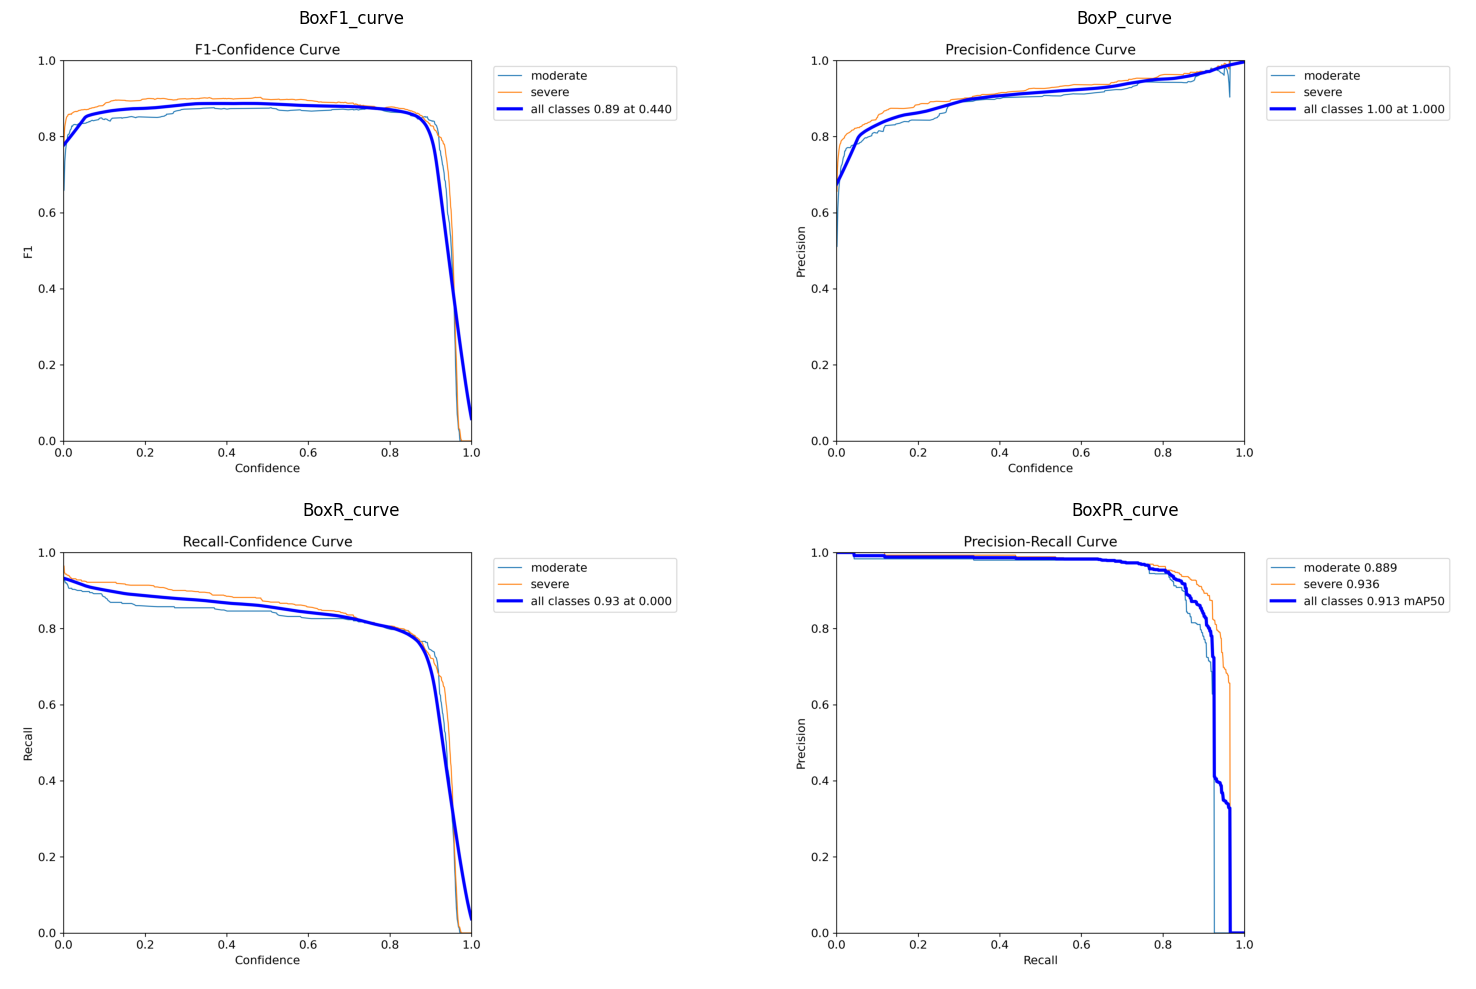

In [8]:
# 指定性能评估曲线的图片所在的目录
directory = '/kaggle/working/runs/detect/train'

# 定义要展示的图片文件名
image_files = [
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png'
]

# 定义一个包含 4 个子图的图形
fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten() # 将二维数组展平为一维数组

# 遍历每个图片文件并加载到相应的子图中
for ax, image_file in zip(axes, image_files):
    image_path = os.path.join(directory, image_file)
    if os.path.exists(image_path):
        img = plt.imread(image_path)
        ax.imshow(img)
        ax.set_title(os.path.splitext(image_file)[0]) # 设置子图标题为图片文件名（去掉扩展名）
        ax.axis('off')
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')

# 调整子图间距
plt.tight_layout()
plt.show()

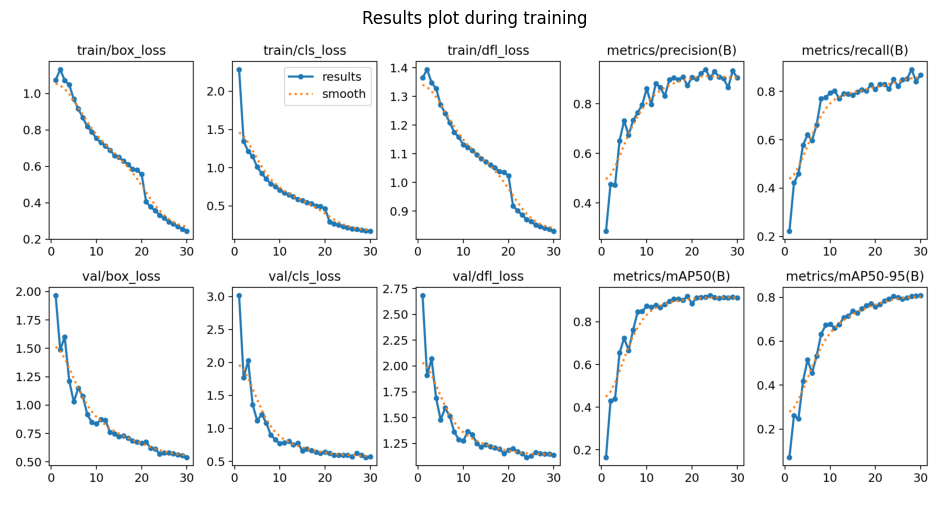

In [9]:
# result.png 图片路径
image_path = '/kaggle/working/runs/detect/train/results.png'
# 读取图片
img = plt.imread(image_path)
# 创建一个图形窗口并显示图片
plt.figure(figsize = (12, 8))
plt.imshow(img)
plt.title('Results plot during training')
plt.axis('off')
plt.show()


image 1/1 /kaggle/input/datasets/justinwshj/accidents/datasets/test/images/accidentFrame3016_jpg.rf.88abe0a009570454b2788a6383013eb4.jpg: 640x640 1 moderate, 10.8ms
Speed: 2.7ms preprocess, 10.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/justinwshj/accidents/datasets/test/images/traffic_img124_jpg.rf.8b78d8b61159e46f77eb038bb8f8208e.jpg: 640x640 1 severe, 10.8ms
Speed: 0.8ms preprocess, 10.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/justinwshj/accidents/datasets/test/images/images-32_jpg.rf.d253663b57437adbefc14526da2f96a7.jpg: 640x640 1 severe, 10.8ms
Speed: 0.8ms preprocess, 10.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/justinwshj/accidents/datasets/test/images/traffic_img649_jpg.rf.dfc40f1c293913f226ad6dea742a957e.jpg: 640x640 1 moderate, 10.8ms
Speed: 1.0ms preprocess, 10.8ms inference, 1.4ms postprocess pe

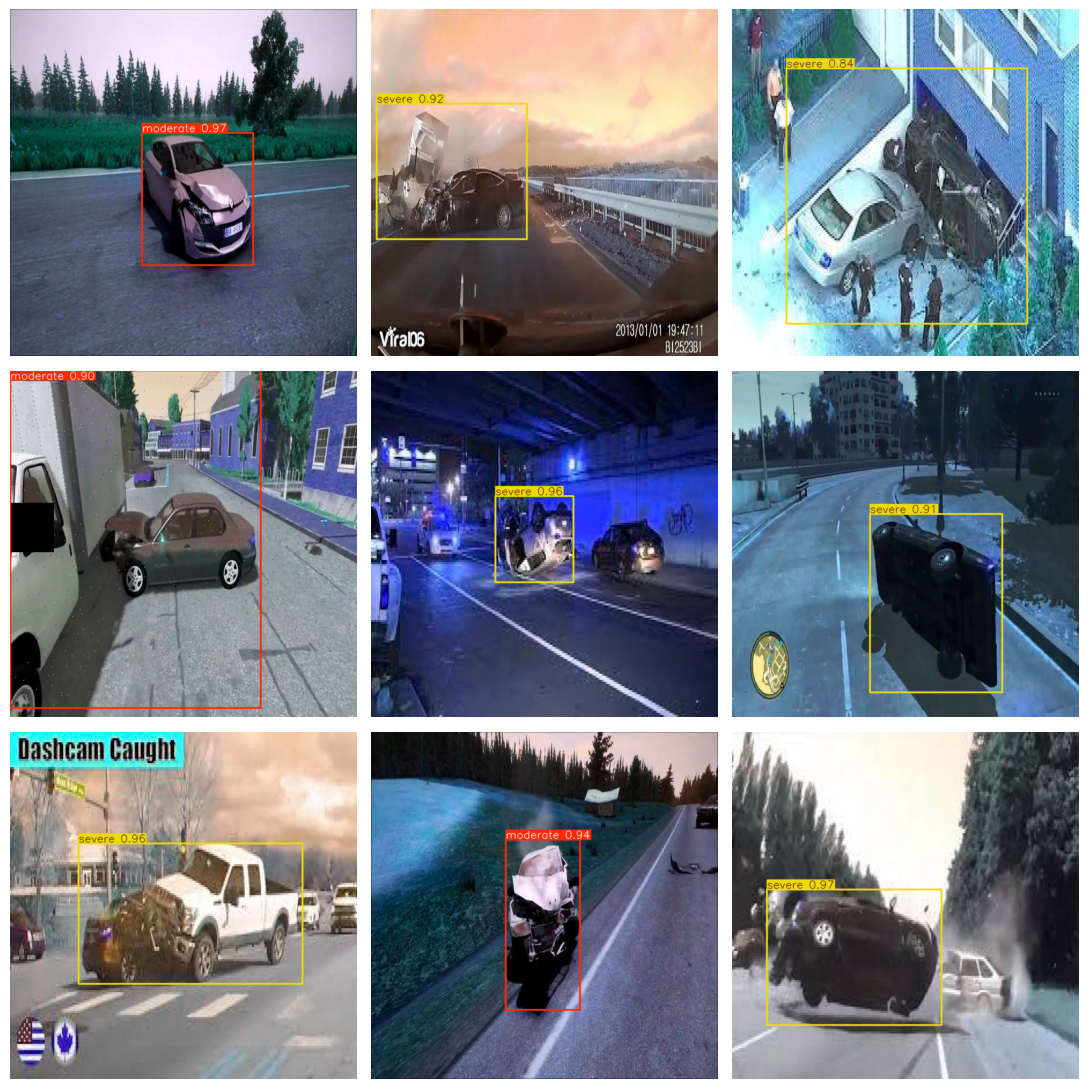

In [10]:
# 对测试集进行预测
# 定义采样数量
num_samples = 9
test_img_dir = '/kaggle/input/datasets/justinwshj/accidents/datasets/test/images'

#获取测试图片目录下的所有图片文件名
image_files = os.listdir(test_img_dir)

#随机选择指定数量的图片文件作为测试图片
test_imgs = random.sample(image_files, num_samples)

# 创建一个 3 * 3 的图幅，用于展示 9 张测试图片的预测结果
fig, axes = plt.subplots(3, 3, figsize = (11, 11))

# 遍历每个测试图片
for i in range(num_samples):
    # 获取当前测试图片的文件名
    image = test_imgs[i]
    # 根据索引确定图片在 3 * 3 图幅中的位置
    ax = axes[i // 3, i % 3]
    # 使用模型对当前测试图片进行预测
    result_predict = model.predict(
        source = os.path.join(test_img_dir, image)
    )
    # 在图幅中的相应位置上展示预测结果
    ax.imshow(result_predict[0].plot())
    # 关闭图片坐标轴显示
    ax.axis('off')

# 调整图幅布局，确保图片标题和图片本身不重叠
plt.tight_layout()
# 显示所有测试图片的预测结果
plt.show()

In [11]:
!zip -q -r results.zip /kaggle/working/*